Tools docs: https://docs.google.com/document/d/189dWz0sP6ySA4htE7svEpLP5-RykpQyfCk2AZpmHwg8/edit?usp=sharing

In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing import Any
import requests
import math
import os

In [3]:
load_dotenv()

True

In [ ]:
# llm = ChatOpenAI()

In [20]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.7,
    streaming=True
)

In [22]:
# Tools
search_tool = TavilySearch(
    max_results=5,
    topic="general",
    search_depth="advanced"
)



@tool
def calculator(expression: str) -> str:
    """
    Useful for simple math calculations.
    Input should be a valid math expression.
    Example: 2 + 2, math.sqrt(16), 10 * 5
    """

    try:
        allowed = {
            "math": math,
            "abs": abs,
            "round": round,
            "min": min,
            "max": max,
            "sum": sum
        }

        result = eval(expression, {"__builtins__": {}}, allowed)
        return str(result)

    except Exception as e:
        return f"Calculation error: {str(e)}"


@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=HTM6MLWOXVJCK77J"
    r = requests.get(url)
    return r.json()



@tool
def get_current_weather(location: str) -> str:
    """
    Get the current real-time weather for a given city or location.

    Args:
        location: City or location name, for example:
                  "Dhaka", "London, UK", or "New York, US".

    Returns:
        A formatted current weather report.
    """

    api_key = os.getenv("OPENWEATHER_API_KEY")

    if not api_key:
        return (
            "Weather API key is missing. "
            "Set the OPENWEATHER_API_KEY environment variable."
        )

    try:
        # Step 1: Convert the location name into latitude and longitude
        geocoding_url = "https://api.openweathermap.org/geo/1.0/direct"

        geocoding_params = {
            "q": location,
            "limit": 1,
            "appid": api_key,
        }

        geo_response = requests.get(
            geocoding_url,
            params=geocoding_params,
            timeout=10,
        )
        geo_response.raise_for_status()

        locations: list[dict[str, Any]] = geo_response.json()

        if not locations:
            return f"Could not find the location: {location}"

        latitude = locations[0]["lat"]
        longitude = locations[0]["lon"]
        resolved_name = locations[0].get("name", location)
        country = locations[0].get("country", "")
        state = locations[0].get("state", "")

        # Step 2: Get current weather using latitude and longitude
        weather_url = "https://api.openweathermap.org/data/2.5/weather"

        weather_params = {
            "lat": latitude,
            "lon": longitude,
            "appid": api_key,
            "units": "metric",
        }

        weather_response = requests.get(
            weather_url,
            params=weather_params,
            timeout=10,
        )
        weather_response.raise_for_status()

        weather_data = weather_response.json()

        temperature = weather_data["main"]["temp"]
        feels_like = weather_data["main"]["feels_like"]
        humidity = weather_data["main"]["humidity"]
        pressure = weather_data["main"]["pressure"]
        description = weather_data["weather"][0]["description"]
        wind_speed = weather_data.get("wind", {}).get("speed", "N/A")
        visibility_meters = weather_data.get("visibility")

        visibility_km = (
            round(visibility_meters / 1000, 1)
            if visibility_meters is not None
            else "N/A"
        )

        location_parts = [resolved_name]

        if state:
            location_parts.append(state)

        if country:
            location_parts.append(country)

        display_location = ", ".join(location_parts)

        return (
            f"Current weather in {display_location}:\n"
            f"- Condition: {description.title()}\n"
            f"- Temperature: {temperature}°C\n"
            f"- Feels like: {feels_like}°C\n"
            f"- Humidity: {humidity}%\n"
            f"- Pressure: {pressure} hPa\n"
            f"- Wind speed: {wind_speed} m/s\n"
            f"- Visibility: {visibility_km} km"
        )

    except requests.Timeout:
        return "The weather service request timed out. Please try again."

    except requests.HTTPError as error:
        status_code = error.response.status_code if error.response else "unknown"

        if status_code == 401:
            return "The OpenWeather API key is invalid or inactive."

        return f"Weather API returned an HTTP error: {status_code}"

    except requests.RequestException as error:
        return f"Could not connect to the weather service: {error}"

    except (KeyError, TypeError, ValueError) as error:
        return f"Unexpected weather API response: {error}"

In [23]:
# Make tool list
tools = [search_tool,calculator, get_stock_price,get_current_weather]

# Make the LLM tool-aware
llm_with_tools = llm.bind_tools(tools)

In [24]:
# state
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [25]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

In [26]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

In [27]:
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")    

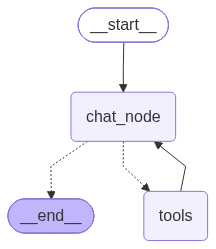

In [28]:
chatbot = graph.compile()

chatbot

In [29]:
# Regular chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)


[{'type': 'text', 'text': 'Hello! How can I help you today?', 'index': 0, 'extras': {'signature': 'EvEBCu4BAWkUfRPUge7C9LYOSnMvR4DgH+SSsw6FwxARzHgLWpHhmwATwNXlVFCjon2Ecdh+V6eQSTkI2hy9sYxg57k1vGjNsoJtFeXfT0DSAfv4cjbCtcW8D90S30R9mPKHZxNvEsdshX733IFcZbEwnMrgx+aLCwFZAMaZexIIMQ1U0n2TNq6OAFaaA9DTbnQnywz/LmRVta++81WslvMN7q/YWGM1+YDfYY18ltQ4+mVM5y5lMoa9tCeoD2HfElxLYgWIk/30/jRtYSjxG4fCtjeOWa20FHtpHxCTe4U5w30lFWXZZqNSZ1HKLxQqbwt2xw=='}}]


In [30]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is 8989898*90909090+5404040?")]})
print(out["messages"][-1].content)

[{'type': 'text', 'text': '$8{,}989{,}898 \\times 90{,}909{,}090 + 5{,}404{,}040 = \\mathbf{817{,}263{,}451{,}776{,}860}$', 'index': 0, 'extras': {'signature': 'EsEDCr4DAWkUfRP8uRVsF4rxSHqkE8MTxINuwaycz/XuYOxN2hWBJpsuBNGbhFKujLrDVZkuWSbCPDZAtfNvuiiVJZSu+klz2vGUqaPxZW6TjNqNCZUQ+CNIelgNskJjJkHIqhkhJaP6iz1WMUpr3hAGrdmAaYGyw62vzPsQTp7Mt048eOMH+X4ojmXCbjk3VZrwKA5YmDi7srAtUpIvZYI+Spw6U/CQ8cEU41yLQ9GnciBdZ77H8Z7nyIKMGbcWFYhdIVxrSS/pmeBgSYXe8RpX29ehYPIPHf5T4WAWLw2jzlnWN7ff2nkcojpKYqAz0zo47iXIuXeBz3LywfvssfpCj5W0WtNCue95QMu6xb250bz5JIIUQuaVieWTshGFcsa1vp9dC2RhpGFMaVBoyEQnXlfKFpYIP7uN1oj1jw+8RzJ0Qft5U1QsbrvJg8N/0P7DV5Hq1jLd5KU4Z6ofNwHDN0eMh1z6b8KuCoM+x7+CYRZWDskSPbIlHfOrOw/CnBfNRcmc+gX7bYF1MaVlyCWUp2mxXp/OTZvEOgXTwuXt/zeVcbchuiEALlXW4gBl/eOKteLEzlwbyan5KLHbURxgDMM='}}]


In [31]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="what is the new movie releases in 2026")]})
print(out["messages"][-1].content[0])

{'type': 'text', 'text': "The film schedule for **2026** is packed with major franchise tentpoles, superhero blockbusters, sequels, and high-profile auteur projects. \n\nHere is a breakdown of the biggest and most anticipated movie releases scheduled for 2026:\n\n---\n\n### **Spring 2026**\n* **Project Hail Mary** *(March 20, 2026)*  \n  * **Cast/Crew:** Directed by Phil Lord & Christopher Miller; stars Ryan Gosling.  \n  * **Premise:** Based on the bestselling sci-fi novel by Andy Weir (*The Martian*), following an astronaut trying to save humanity from an extinction-level solar crisis.\n* **The Super Mario Bros. Movie 2** *(April 3, 2026)*  \n  * **Cast/Crew:** Illumination & Nintendo; stars Chris Pratt, Anya Taylor-Joy, Charlie Day, Jack Black.  \n  * **Premise:** The follow-up to the $1.3B+ animated mega-hit.\n* **Michael** *(April 2026)*  \n  * **Cast/Crew:** Directed by Antoine Fuqua; stars Jaafar Jackson and Colman Domingo.  \n  * **Premise:** The long-awaited official biopic ch

In [32]:
print(out["messages"][-1].content[0]['text'])

The film schedule for **2026** is packed with major franchise tentpoles, superhero blockbusters, sequels, and high-profile auteur projects. 

Here is a breakdown of the biggest and most anticipated movie releases scheduled for 2026:

---

### **Spring 2026**
* **Project Hail Mary** *(March 20, 2026)*  
  * **Cast/Crew:** Directed by Phil Lord & Christopher Miller; stars Ryan Gosling.  
  * **Premise:** Based on the bestselling sci-fi novel by Andy Weir (*The Martian*), following an astronaut trying to save humanity from an extinction-level solar crisis.
* **The Super Mario Bros. Movie 2** *(April 3, 2026)*  
  * **Cast/Crew:** Illumination & Nintendo; stars Chris Pratt, Anya Taylor-Joy, Charlie Day, Jack Black.  
  * **Premise:** The follow-up to the $1.3B+ animated mega-hit.
* **Michael** *(April 2026)*  
  * **Cast/Crew:** Directed by Antoine Fuqua; stars Jaafar Jackson and Colman Domingo.  
  * **Premise:** The long-awaited official biopic chronicling the life and legacy of Michael 

In [33]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?")]})
print(out["messages"][-1].content)

[{'type': 'text', 'text': 'The current stock price of Apple (AAPL) is **$343.46** per share.\n\nTo purchase 50 shares:\n$$\\text{Total Cost} = 50 \\times 343.46 = \\$17,173.00$$\n\nIt will cost **$17,173.00** to purchase 50 shares of Apple.', 'index': 0, 'extras': {'signature': 'EsYBCsMBAWkUfRMu3uNOxqHwp+MVfTN4iJh9jJs/f5OUcc9jYqkH3V/Xo0xp4U2vO/WWATz6ffGWqfl1hlGAOMRP4ozZcDEdiMaQd4w6SFWUbUVxTpkmcRR/gcg9skzsuvo60JQN80nimi88hO1mugh0GX4U5G0b+6VjlH6N4FFpOFmkSQVuYYERHLVNmKzi5hwxOYjb/eSBJX6ssXBt6vvUNZbwsJePcwB0lompnQ2qJMqKKLxY6DIVPWPlROOhda7j0DohZmEI'}}]


In [34]:
print(out["messages"][-1].content[0]['text'])

The current stock price of Apple (AAPL) is **$343.46** per share.

To purchase 50 shares:
$$\text{Total Cost} = 50 \times 343.46 = \$17,173.00$$

It will cost **$17,173.00** to purchase 50 shares of Apple.


In [ ]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is the current weather in Delhi?")]})
print(out["messages"][-1].content)

ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 12h53m22.603591853s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model': 'gemini-3.8-fl

: 